In [1]:
import os
import pandas as pd

# Dirección de HDFS por WebHDFS (viene de las variables de entorno del contenedor)
HOST = os.environ.get('HDFS_WEBHDFS_URL', 'http://namenode:9870').replace('http://', '')
OPT = {'user': os.environ.get('HDFS_USER', 'root')}   # usuario con el que se accede a HDFS
RAW = f'webhdfs://{HOST}/datalake/raw'
CLEAN = f'webhdfs://{HOST}/datalake/clean'
print(RAW)

webhdfs://namenode:9870/datalake/raw


In [2]:
# Leemos el CSV COMPLETO desde HDFS (en la celda anterior ya definimos RAW y OPT).
# dtype=str: todo como texto, para no perder los valores sucios y decidir nosotros cómo limpiarlos.
# keep_default_na=False: los vacíos quedan como '' (si no, pandas los esconde como NaN
#   y también convierte textos como "NA" o "None" sin avisar).
# encoding='utf-8-sig': el CSV lleva BOM.
df_raw = pd.read_csv(
    f'{RAW}/pedidos_tiempos_preparacion/02_pedidos_tiempos_preparacion.csv',
    storage_options=OPT,
    dtype=str,
    encoding='utf-8-sig',
    keep_default_na=False,
)

# df_raw es la copia sin tocar: nunca la modificamos, trabajaremos sobre copias.
print('Filas y columnas:', df_raw.shape)
df_raw.head()

Filas y columnas: (115590, 25)


,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,pedido_pendiente,cocineros_disponibles,tiempo_prep_min,canal,...,franja,es_hora_punta,mes,ocupacion_local,comensales,num_platos_complejos,temperatura_c,precipitacion_mm,evento_local,ingrediente_agotado
0,PED-0000001,2023-01-01,10:07:00,7,1,6.00,1,5,11.0,mesa,...,manana,0,1,0.05,1,0,4.2,0.0,ninguno,0
1,PED-0000002,2023-01-01,10:32:00,7,2,4.00,1,4,00:15,delivery,...,manana,0,1,0.04,2,0,4.2,0.0,ninguno,0
2,PED-0000003,2023-01-01,11:22:00,7,2,5.50,1,5,17.6,delivery,...,manana,0,1,0.15,2,1,4.2,0.0,ninguno,0
3,PED-0000004,2023-01-01,11:34:00,7,3,2.67,0,3,18.6,delivery,...,manana,0,1,0.15,3,0,4.2,0.0,ninguno,0
4,PED-0000005,2023-01-01,11:36:00,7,4,3.00,4,3,25.3,delivery,...,manana,0,1,0.19,2,0,4.2,0.0,ninguno,0


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta Smart Restaurant
AZUL, NARANJA, GRIS, MELOCOTON, TEXTO = "#1F3A44", "#F28C38", "#5C808E", "#FFE0C2", "#162930"
sns.set_theme(style="whitegrid", palette=[AZUL, NARANJA, GRIS, MELOCOTON], font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlecolor": AZUL,
                     "axes.labelcolor": TEXTO, "xtick.color": TEXTO, "ytick.color": TEXTO})

print("Filas:", f"{len(df_raw):,}", "| Columnas:", df_raw.shape[1])
print(f"Memoria: {df_raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Valores distintos por columna y un ejemplo (todo es texto porque leímos con dtype=str)
resumen = pd.DataFrame({"valores_distintos": df_raw.nunique(), "ejemplo": df_raw.iloc[0]})
display(resumen)

Filas: 115,590 | Columnas: 25
Memoria: 175.7 MB


,valores_distintos,ejemplo
id_pedido,114990,PED-0000001
fecha,1726,2023-01-01
hora,781,10:07:00
dia_semana,10,7
n_platos,9,1
complejidad_pedido,151,6.00
pedido_pendiente,22,1
cocineros_disponibles,8,5
tiempo_prep_min,605,11.0
canal,3,mesa


,vacios,pct
n_platos,533,0.46
complejidad_pedido,533,0.46
tiempo_prep_min,521,0.45
cocineros_disponibles,509,0.44
dia_semana,505,0.44
hora,499,0.43
pedido_pendiente,485,0.42
fecha,454,0.39


Columnas SIN ningún vacío: ['id_pedido', 'canal', 'prioridad_aux', 'id_local', 'estado_captura', 'es_fin_de_semana', 'es_festivo', 'franja', 'es_hora_punta', 'mes', 'ocupacion_local', 'comensales', 'num_platos_complejos', 'temperatura_c', 'precipitacion_mm', 'evento_local', 'ingrediente_agotado']


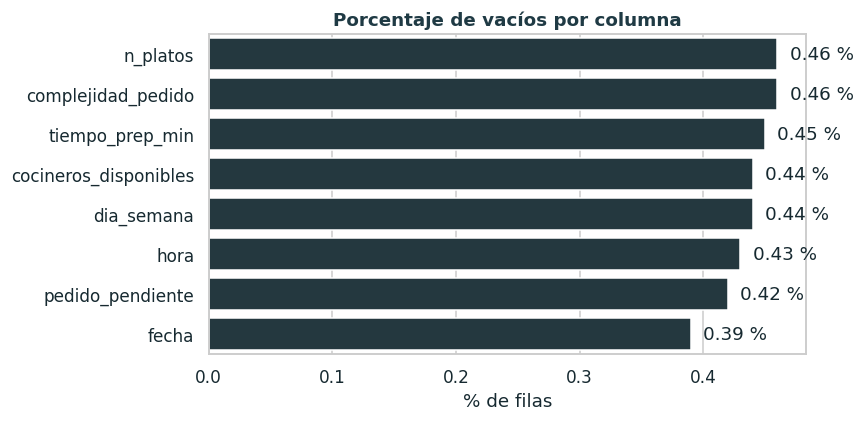

Filas con al menos un vacío: 3,463 (3.0 %)


In [4]:
# Un vacío es '' o solo espacios (con keep_default_na=False no aparecen como NaN)
vacios = df_raw.apply(lambda s: s.str.strip() == "").sum()
tabla_vacios = pd.DataFrame({"vacios": vacios, "pct": (vacios / len(df_raw) * 100).round(2)})
tabla_vacios = tabla_vacios[tabla_vacios["vacios"] > 0].sort_values("vacios", ascending=False)
display(tabla_vacios)
print("Columnas SIN ningún vacío:", [c for c in df_raw.columns if c not in tabla_vacios.index])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=tabla_vacios["pct"], y=tabla_vacios.index, color=AZUL, ax=ax)
ax.set(title="Porcentaje de vacíos por columna", xlabel="% de filas", ylabel="")
for i, v in enumerate(tabla_vacios["pct"]):
    ax.text(v + 0.01, i, f"{v:.2f} %", va="center", color=TEXTO)
plt.tight_layout()
plt.show()

# Cuántas filas tienen al menos un vacío
filas_con_vacio = df_raw.apply(lambda s: s.str.strip() == "").any(axis=1).sum()
print(f"Filas con al menos un vacío: {filas_con_vacio:,} ({filas_con_vacio / len(df_raw) * 100:.1f} %)")

In [5]:
numericas = ["dia_semana", "n_platos", "complejidad_pedido", "pedido_pendiente",
             "cocineros_disponibles", "tiempo_prep_min", "id_local", "mes", "ocupacion_local",
             "comensales", "num_platos_complejos", "temperatura_c", "precipitacion_mm"]

for col in numericas:
    s = df_raw[col].str.strip()
    # raros = no vacíos pero que to_numeric no entiende (ej. 'lunes', '00:25')
    raros = s[(s != "") & pd.to_numeric(s, errors="coerce").isna()]
    print(f"{col:24s} {len(raros):5d} no numéricos", dict(raros.value_counts().head(5)) if len(raros) else "")

dia_semana                 342 no numéricos {'lunes': np.int64(342)}
n_platos                     0 no numéricos 
complejidad_pedido           0 no numéricos 
pedido_pendiente             0 no numéricos 
cocineros_disponibles        0 no numéricos 
tiempo_prep_min            924 no numéricos {'00:20': np.int64(65), '00:24': np.int64(57), '00:22': np.int64(52), '00:25': np.int64(51), '00:21': np.int64(51)}
id_local                     0 no numéricos 
mes                          0 no numéricos 
ocupacion_local              0 no numéricos 
comensales                   0 no numéricos 
num_platos_complejos         0 no numéricos 
temperatura_c                0 no numéricos 
precipitacion_mm             0 no numéricos 


In [6]:
print("Filas totalmente duplicadas:", df_raw.duplicated().sum())
print("id_pedido repetidos:        ", df_raw["id_pedido"].duplicated().sum())

# ¿Son copias exactas o el mismo id con datos distintos?
rep = df_raw[df_raw["id_pedido"].duplicated(keep=False)]
distintas = rep.drop_duplicates().groupby("id_pedido").size().gt(1).sum()
print("IDs repetidos con datos DISTINTOS:", distintas)
display(rep.sort_values("id_pedido").head(4))

Filas totalmente duplicadas: 600
id_pedido repetidos:         600
IDs repetidos con datos DISTINTOS: 0


,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,pedido_pendiente,cocineros_disponibles,tiempo_prep_min,canal,...,franja,es_hora_punta,mes,ocupacion_local,comensales,num_platos_complejos,temperatura_c,precipitacion_mm,evento_local,ingrediente_agotado
39,PED-0000040,2023-01-01,14:11:00,7,2,4.50,20,4,42.6,mesa,...,comida,1,1,1.09,1,0,4.2,0.0,ninguno,0
40,PED-0000040,2023-01-01,14:11:00,7,2,4.50,20,4,42.6,mesa,...,comida,1,1,1.09,1,0,4.2,0.0,ninguno,0
289,PED-0000289,2023-01-04,13:49:00,3,4,3.75,6,6,22.4,delivery,...,comida,1,1,0.43,3,0,4.9,0.0,ninguno,0
290,PED-0000289,2023-01-04,13:49:00,3,4,3.75,6,6,22.4,delivery,...,comida,1,1,0.43,3,0,4.9,0.0,ninguno,0


In [7]:
# Cambiamos cada dígito por 9 y cada grupo de letras por 'a' para ver los patrones
patron = lambda s: s.str.replace(r"\d", "9", regex=True).str.replace(r"[a-zA-Z]+", "a", regex=True)

for col in ["id_pedido", "fecha", "hora", "tiempo_prep_min", "dia_semana"]:
    print(f"\nPatrones de {col}:")
    print(patron(df_raw[col]).value_counts().head(8).to_string())


Patrones de id_pedido:
id_pedido
a-9999999    115590

Patrones de fecha:
fecha
9999-99-99    113367
99-99-9999      1769
                 454

Patrones de hora:
hora
99:99:99    115091
               499

Patrones de tiempo_prep_min:
tiempo_prep_min
99.9     113465
99:99       924
9.9         680
            521

Patrones de dia_semana:
dia_semana
9    114743
        505
a       342


In [8]:
categoricas = ["canal", "prioridad_aux", "estado_captura", "franja", "evento_local", "id_local",
               "es_fin_de_semana", "es_festivo", "es_hora_punta", "ingrediente_agotado"]
for col in categoricas:
    print(f"\n{col} ({df_raw[col].nunique()} valores):")
    print(df_raw[col].value_counts().head(15).to_dict())

# Una columna con un solo valor no aporta información
print("\nColumnas constantes:", [c for c in df_raw.columns if df_raw[c].nunique() == 1])


canal (3 valores):
{'mesa': 59138, 'delivery': 32574, 'takeaway': 23878}

prioridad_aux (3 valores):
{'normal': 86843, 'prioridad': 20800, 'VIP': 7947}

estado_captura (1 valores):
{'registrado': 115590}

franja (4 valores):
{'comida': 53820, 'cena': 44457, 'tarde': 13748, 'manana': 3565}

evento_local (4 valores):
{'ninguno': 108785, 'semana_grande': 3249, 'navidad': 3149, 'tamborrada': 407}

id_local (12 valores):
{'1': 11640, '2': 11436, '7': 11272, '4': 11141, '11': 9986, '6': 9695, '10': 9564, '8': 9463, '9': 8669, '12': 8268, '5': 7833, '3': 6623}

es_fin_de_semana (2 valores):
{'0': 66271, '1': 49319}

es_festivo (2 valores):
{'0': 110293, '1': 5297}

es_hora_punta (2 valores):
{'1': 66355, '0': 49235}

ingrediente_agotado (2 valores):
{'0': 112444, '1': 3146}

Columnas constantes: ['estado_captura']


In [9]:
# Tiempo: '00:25' (HH:MM) -> 25 minutos; el resto es número normal
t = df_raw["tiempo_prep_min"].str.strip()
hhmm = t.str.fullmatch(r"\d{1,2}:\d{2}")
tiempo = pd.to_numeric(t.where(~hhmm), errors="coerce")
tiempo[hhmm] = t[hhmm].str.split(":").str[0].astype(int) * 60 + t[hhmm].str.split(":").str[1].astype(int)

# Copia numérica SOLO para mirar rangos (df_raw no se toca)
num = pd.DataFrame({c: pd.to_numeric(df_raw[c].str.strip(), errors="coerce") for c in numericas})
num["tiempo_prep_min"] = tiempo
display(num.describe().round(2).T[["count", "min", "50%", "mean", "max"]])

# Valores fuera del rango esperado
fuera = {
    "dia_semana (1-7)": ~num["dia_semana"].between(1, 7) & num["dia_semana"].notna(),
    "n_platos (1-8)": ~num["n_platos"].between(1, 8) & num["n_platos"].notna(),
    "cocineros (1-8)": ~num["cocineros_disponibles"].between(1, 8) & num["cocineros_disponibles"].notna(),
    "tiempo (1-120)": ~num["tiempo_prep_min"].between(1, 120) & num["tiempo_prep_min"].notna(),
}
print("Fuera de rango:", {k: int(v.sum()) for k, v in fuera.items()})

# Fechas: dos formatos (AAAA-MM-DD y MM-DD-AAAA)
f = df_raw["fecha"].str.strip()
iso = pd.to_datetime(f, format="%Y-%m-%d", errors="coerce")
mdy = pd.to_datetime(f, format="%m-%d-%Y", errors="coerce")
print("Fechas ISO:", iso.notna().sum(), "| MM-DD-AAAA:", (iso.isna() & mdy.notna()).sum(),
      "| vacías:", (iso.isna() & mdy.isna()).sum())
print("Rango:", iso.min().date(), "->", iso.max().date())

,count,min,50%,mean,max
dia_semana,114743.0,0.00,5.00,4.84,8.0
n_platos,115057.0,1.00,3.00,3.41,8.0
complejidad_pedido,115057.0,1.00,4.50,4.59,10.0
pedido_pendiente,115105.0,0.00,7.00,7.73,20.0
cocineros_disponibles,115081.0,1.00,5.00,4.82,7.0
tiempo_prep_min,115069.0,3.00,24.50,25.36,60.0
id_local,115590.0,1.00,6.00,6.35,12.0
mes,115590.0,1.00,7.00,6.58,12.0
ocupacion_local,115590.0,0.02,0.47,0.52,1.3
comensales,115590.0,1.00,2.00,2.51,8.0


Fuera de rango: {'dia_semana (1-7)': 803, 'n_platos (1-8)': 0, 'cocineros (1-8)': 0, 'tiempo (1-120)': 0}
Fechas ISO: 113367 | MM-DD-AAAA: 1769 | vacías: 454
Rango: 2023-01-01 -> 2025-12-31


In [10]:
# Trabajamos sobre una copia: df_raw (el original) nunca se modifica
df = df_raw.copy()
n_antes = df.shape[1]

# 1) Columnas sin información para el objetivo (tiempo_prep_min)
#    - estado_captura: vale 'registrado' en todas las filas (constante)
#    - temperatura_c y mes: sin relación con el tiempo (r ~ 0,01-0,02, importancia 0)
COLUMNAS_SIN_INFO = ["estado_captura", "temperatura_c", "mes"]

# 2) Redundantes: su efecto ya lo recogen pedido_pendiente, cocineros_disponibles y n_platos.
#    NO se quitan ahora (sirven para el EDA y el dashboard); se quitarán al preparar el dataset del modelo.
COLUMNAS_REDUNDANTES = ["comensales", "ocupacion_local", "es_hora_punta", "es_fin_de_semana",
                        "es_festivo", "evento_local", "franja"]

df = df.drop(columns=COLUMNAS_SIN_INFO)

print(f"Columnas: {n_antes} -> {df.shape[1]}")
print("Eliminadas:", COLUMNAS_SIN_INFO)
print("Se mantienen por ahora (redundantes):", COLUMNAS_REDUNDANTES)
print("\nColumnas actuales:", list(df.columns))

Columnas: 25 -> 22
Eliminadas: ['estado_captura', 'temperatura_c', 'mes']
Se mantienen por ahora (redundantes): ['comensales', 'ocupacion_local', 'es_hora_punta', 'es_fin_de_semana', 'es_festivo', 'evento_local', 'franja']

Columnas actuales: ['id_pedido', 'fecha', 'hora', 'dia_semana', 'n_platos', 'complejidad_pedido', 'pedido_pendiente', 'cocineros_disponibles', 'tiempo_prep_min', 'canal', 'prioridad_aux', 'id_local', 'es_fin_de_semana', 'es_festivo', 'franja', 'es_hora_punta', 'ocupacion_local', 'comensales', 'num_platos_complejos', 'precipitacion_mm', 'evento_local', 'ingrediente_agotado']


In [12]:
# Columnas redundantes: su efecto sobre tiempo_prep_min ya lo recogen
# pedido_pendiente, cocineros_disponibles y n_platos
# (por ejemplo, comensales ~ n_platos con r = 0,81 y ocupacion_local ~ pedido_pendiente con r = 0,82)
COLUMNAS_REDUNDANTES = ["comensales", "ocupacion_local", "es_hora_punta", "es_fin_de_semana",
                        "es_festivo", "evento_local", "franja"]

n_antes = df.shape[1]
df = df.drop(columns=COLUMNAS_REDUNDANTES)

print(f"Columnas: {n_antes} -> {df.shape[1]}")
print("Eliminadas:", COLUMNAS_REDUNDANTES)
print("\nColumnas actuales:", list(df.columns))

Columnas: 22 -> 15
Eliminadas: ['comensales', 'ocupacion_local', 'es_hora_punta', 'es_fin_de_semana', 'es_festivo', 'evento_local', 'franja']

Columnas actuales: ['id_pedido', 'fecha', 'hora', 'dia_semana', 'n_platos', 'complejidad_pedido', 'pedido_pendiente', 'cocineros_disponibles', 'tiempo_prep_min', 'canal', 'prioridad_aux', 'id_local', 'num_platos_complejos', 'precipitacion_mm', 'ingrediente_agotado']


In [13]:
df

,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,pedido_pendiente,cocineros_disponibles,tiempo_prep_min,canal,prioridad_aux,id_local,num_platos_complejos,precipitacion_mm,ingrediente_agotado
0,PED-0000001,2023-01-01,10:07:00,7,1,6.00,1,5,11.0,mesa,prioridad,7,0,0.0,0
1,PED-0000002,2023-01-01,10:32:00,7,2,4.00,1,4,00:15,delivery,normal,8,0,0.0,0
2,PED-0000003,2023-01-01,11:22:00,7,2,5.50,1,5,17.6,delivery,normal,1,1,0.0,0
3,PED-0000004,2023-01-01,11:34:00,7,3,2.67,0,3,18.6,delivery,normal,12,0,0.0,0
4,PED-0000005,2023-01-01,11:36:00,7,4,3.00,4,3,25.3,delivery,prioridad,9,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115585,PED-0114986,2025-12-31,21:59:00,3,8,4.00,3,4,33.0,mesa,normal,5,2,2.4,0
115586,PED-0114987,2025-12-31,22:14:00,3,4,4.50,4,5,25.8,delivery,normal,4,1,2.4,0
115587,PED-0114988,2025-12-31,22:19:00,3,5,6.40,2,5,28.9,delivery,normal,6,2,2.4,0
115588,PED-0114989,2025-12-31,22:29:00,3,4,4.00,4,4,19.4,mesa,normal,9,1,2.4,0


In [14]:
df = df.drop(columns=["id_local"])

In [15]:
df

,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,pedido_pendiente,cocineros_disponibles,tiempo_prep_min,canal,prioridad_aux,num_platos_complejos,precipitacion_mm,ingrediente_agotado
0,PED-0000001,2023-01-01,10:07:00,7,1,6.00,1,5,11.0,mesa,prioridad,0,0.0,0
1,PED-0000002,2023-01-01,10:32:00,7,2,4.00,1,4,00:15,delivery,normal,0,0.0,0
2,PED-0000003,2023-01-01,11:22:00,7,2,5.50,1,5,17.6,delivery,normal,1,0.0,0
3,PED-0000004,2023-01-01,11:34:00,7,3,2.67,0,3,18.6,delivery,normal,0,0.0,0
4,PED-0000005,2023-01-01,11:36:00,7,4,3.00,4,3,25.3,delivery,prioridad,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115585,PED-0114986,2025-12-31,21:59:00,3,8,4.00,3,4,33.0,mesa,normal,2,2.4,0
115586,PED-0114987,2025-12-31,22:14:00,3,4,4.50,4,5,25.8,delivery,normal,1,2.4,0
115587,PED-0114988,2025-12-31,22:19:00,3,5,6.40,2,5,28.9,delivery,normal,2,2.4,0
115588,PED-0114989,2025-12-31,22:29:00,3,4,4.00,4,4,19.4,mesa,normal,1,2.4,0


In [16]:
# Copias exactas con el mismo id_pedido (son 600)
n0 = len(df)
df = df.drop_duplicates(subset="id_pedido", keep="first").reset_index(drop=True)
print(f"Duplicados eliminados: {n0 - len(df):,} -> {len(df):,} filas")
print("id_pedido único:", df["id_pedido"].is_unique)

Duplicados eliminados: 600 -> 114,990 filas
id_pedido único: True


In [17]:
# Enteros (Int64 admite vacíos) y decimales
for c in ["n_platos", "pedido_pendiente", "cocineros_disponibles", "num_platos_complejos", "ingrediente_agotado"]:
    df[c] = pd.to_numeric(df[c].str.strip(), errors="coerce").astype("Int64")
for c in ["complejidad_pedido", "precipitacion_mm"]:
    df[c] = pd.to_numeric(df[c].str.strip(), errors="coerce")

# Objetivo: '00:25' (HH:MM) -> 25 minutos; el resto ya es un número normal
t = df["tiempo_prep_min"].str.strip()
es_hhmm = t.str.fullmatch(r"\d{1,2}:\d{2}")
partes = t[es_hhmm].str.split(":", expand=True).astype(int)
tiempo = pd.to_numeric(t.where(~es_hhmm), errors="coerce")
tiempo[es_hhmm] = partes[0] * 60 + partes[1]
df["tiempo_prep_min"] = tiempo

# Categóricas
for c in ["canal", "prioridad_aux"]:
    df[c] = df[c].astype("category")

print(f"tiempo_prep_min en HH:MM convertidos: {es_hhmm.sum()}")
print(df.dtypes.to_string())

tiempo_prep_min en HH:MM convertidos: 921
id_pedido                  object
fecha                      object
hora                       object
dia_semana                 object
n_platos                    Int64
complejidad_pedido        float64
pedido_pendiente            Int64
cocineros_disponibles       Int64
tiempo_prep_min           float64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64


In [18]:
# --- Fecha: dos formatos (AAAA-MM-DD y MM-DD-AAAA)
fe = df["fecha"].str.strip()
iso = fe.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
mdy = fe.str.fullmatch(r"\d{2}-\d{2}-\d{4}")
fecha = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
fecha[iso] = pd.to_datetime(fe[iso], format="%Y-%m-%d")
fecha[mdy] = pd.to_datetime(fe[mdy], format="%m-%d-%Y")

# --- Hora decimal (20:30 -> 20.5)
h = pd.to_datetime(df["hora"].str.strip(), format="%H:%M:%S", errors="coerce")
hora_dec = h.dt.hour + h.dt.minute / 60

# El id_pedido crece con la fecha y la hora, así que df está en orden cronológico.
def rellenar_fecha(f, hd):
    f = f.copy()
    # 1) Misma fecha en la fila de arriba y en la de abajo -> esa misma fecha
    ant, sig = f.ffill(), f.bfill()
    f = f.where(f.notna(), ant.where(ant == sig))

    # 2) Fechas distintas arriba y abajo -> decide la hora.
    #    Anclas = filas vecinas con fecha Y hora conocidas.
    ok = f.notna() & hd.notna()
    f_ant, h_ant = f.where(ok).ffill(), hd.where(ok).ffill()
    f_sig, h_sig = f.where(ok).bfill(), hd.where(ok).bfill()
    pend = f.isna() & hd.notna() & f_ant.notna() & f_sig.notna()
    cabe_ant = hd >= h_ant                  # hora posterior a la de arriba: puede ser su mismo día
    cabe_sig = hd <= h_sig                  # hora anterior a la de abajo: puede ser su mismo día
    d_ant, d_sig = hd - h_ant, h_sig - hd   # horas de distancia a cada vecino
    # Si solo cabe en un día, ese; si caben los dos, el del vecino más cercano en hora
    usa_ant = pend & cabe_ant & (~cabe_sig | (d_ant <= d_sig))
    usa_sig = pend & cabe_sig & (~cabe_ant | (d_ant > d_sig))
    f = f.where(~usa_ant, f_ant)
    f = f.where(~usa_sig, f_sig)
    return f

# Una hora vacía dentro del mismo día se estima con la media de las horas vecinas
def rellenar_hora(hd, f):
    ant, sig = hd.ffill(), hd.bfill()
    mismo_dia = f.eq(f.ffill()) & f.eq(f.bfill())
    return hd.where(hd.notna(), ((ant + sig) / 2).where(mismo_dia & (ant <= sig)))

# Validación: ocultamos 3000 fechas y 3000 horas CONOCIDAS y comprobamos el relleno
rng = np.random.default_rng(0)
idx_f = rng.choice(fecha.index[fecha.notna() & hora_dec.notna()], size=3000, replace=False)
f_test = fecha.copy(); f_test[idx_f] = pd.NaT
rel = rellenar_fecha(f_test, hora_dec); ok = rel[idx_f].notna()
print(f"[fecha] rellenadas {ok.mean()*100:.1f} % | acierto {(rel[idx_f][ok] == fecha[idx_f][ok]).mean()*100:.1f} %")
idx_h = rng.choice(hora_dec.index[hora_dec.notna() & fecha.notna()], size=3000, replace=False)
h_test = hora_dec.copy(); h_test[idx_h] = np.nan
relh = rellenar_hora(h_test, fecha); okh = relh[idx_h].notna()
print(f"[hora]  rellenadas {okh.mean()*100:.1f} % | error medio {(relh[idx_h][okh] - hora_dec[idx_h][okh]).abs().mean()*60:.0f} min")

# Relleno real: fecha -> hora -> fecha otra vez (con las horas ya rellenadas)
n_f0, n_h0 = fecha.isna().sum(), hora_dec.isna().sum()
fecha = rellenar_fecha(fecha, hora_dec)
hora_dec = rellenar_hora(hora_dec, fecha).round(2)
fecha = rellenar_fecha(fecha, hora_dec)
print(f"fechas vacías: {n_f0} -> {fecha.isna().sum()} | horas vacías: {n_h0} -> {hora_dec.isna().sum()}")
print("Orden cronológico correcto:", fecha.dropna().is_monotonic_increasing)

# --- Día de la semana: manda la fecha (1 = lunes ... 7 = domingo)
dia_texto = pd.to_numeric(df["dia_semana"].str.strip(), errors="coerce")
valido = dia_texto.between(1, 7)
dia_fecha = fecha.dt.dayofweek + 1
comparables = valido & fecha.notna()
print(f"dia_semana válido coincide con la fecha en {(dia_texto[comparables] == dia_fecha[comparables]).mean()*100:.1f} % de las filas")
dia = dia_fecha.where(fecha.notna(), dia_texto.where(valido))

df["fecha"], df["hora_dec"], df["dia_semana"] = fecha, hora_dec, dia.astype("Int64")
df = df.drop(columns="hora")
print("\nVacíos que quedan:"); print(df.isna().sum().to_string())

[fecha] rellenadas 100.0 % | acierto 100.0 %
[hora]  rellenadas 98.0 % | error medio 3 min
fechas vacías: 454 -> 0 | horas vacías: 494 -> 7
Orden cronológico correcto: True
dia_semana válido coincide con la fecha en 100.0 % de las filas

Vacíos que quedan:
id_pedido                  0
fecha                      0
dia_semana                 0
n_platos                 532
complejidad_pedido       532
pedido_pendiente         484
cocineros_disponibles    507
tiempo_prep_min          516
canal                      0
prioridad_aux              0
num_platos_complejos       0
precipitacion_mm           0
ingrediente_agotado        0
hora_dec                   7


In [19]:
# Formato DD-MM-AAAA (queda como texto, p. ej. '27-03-2024')
df["fecha"] = df["fecha"].dt.strftime("%d-%m-%Y")

print(df["fecha"].head())
print("Vacíos en fecha:", df["fecha"].isna().sum())

0    01-01-2023
1    01-01-2023
2    01-01-2023
3    01-01-2023
4    01-01-2023
Name: fecha, dtype: object
Vacíos en fecha: 0


In [20]:
# Las horas vacías que quedan son el primer o el último pedido de un día:
# solo uno de los vecinos comparte fecha. Usamos el límite del día como segundo vecino.
HORA_APERTURA, HORA_CIERRE = 10.0, 23.0   # en el CSV los pedidos van de 10:00 a 22:59

vacia = hora_dec.isna() & fecha.notna()
mismo_arriba = fecha.eq(fecha.shift(1))    # comparte día con la fila de arriba
mismo_abajo = fecha.eq(fecha.shift(-1))    # comparte día con la fila de abajo

ultimo = vacia & mismo_arriba & ~mismo_abajo     # último pedido del día
primero = vacia & ~mismo_arriba & mismo_abajo    # primer pedido del día

# Punto medio entre la hora del vecino y el límite del día
hora_dec = hora_dec.where(~ultimo, (hora_dec.shift(1) + HORA_CIERRE) / 2)
hora_dec = hora_dec.where(~primero, (HORA_APERTURA + hora_dec.shift(-1)) / 2)
hora_dec = hora_dec.round(2)

print("horas vacías tras esta regla:", hora_dec.isna().sum())

horas vacías tras esta regla: 0


In [21]:
# Guardamos qué horas estaban vacías ANTES de rellenar (para poder revisarlas después)
hora_vacia_original = hora_dec.isna()

In [22]:
# Pasamos a df para poder agrupar por día (fecha aún como fecha real o como texto, da igual)
df["fecha"], df["hora_dec"] = fecha, hora_dec

# 1) No queda ninguna vacía
print("1) Horas vacías:", df["hora_dec"].isna().sum())

# 2) Todas dentro del horario de los datos (10:00 a 22:59)
fuera = ~df["hora_dec"].between(10, 23, inclusive="left")
print("2) Horas fuera de 10:00-22:59:", int(fuera.sum()))

# 3) Los pedidos van en orden cronológico, así que dentro de cada día la hora solo puede subir
orden = df.groupby("fecha")["hora_dec"].apply(lambda s: s.is_monotonic_increasing)
print(f"3) Días con las horas en orden: {int(orden.sum())} de {len(orden)}")

# 4) Las rellenadas no deben cambiar la distribución
rell = hora_vacia_original & df["hora_dec"].notna()
print("4) Horas rellenadas:", int(rell.sum()))
print("   media rellenadas: %.2f | media originales: %.2f" % (
    df.loc[rell, "hora_dec"].mean(), df.loc[~hora_vacia_original, "hora_dec"].mean()))

# 5) A ojo: 4 horas rellenadas con la fila de arriba y la de abajo
for i in df.index[rell][:4]:
    print(df.loc[max(i-1, 0):i+1, ["id_pedido", "fecha", "hora_dec"]].assign(rellenada=rell).to_string(header=False))
    print("   ---")

1) Horas vacías: 0
2) Horas fuera de 10:00-22:59: 0
3) Días con las horas en orden: 939 de 939
4) Horas rellenadas: 0
   media rellenadas: nan | media originales: 17.22


In [23]:
# n_platos vacío: no se puede reconstruir con fiabilidad (es la 3ª variable más importante)
# complejidad_pedido está vacía exactamente en las mismas filas, así que sale con ellas
n0 = len(df)
df = df[df["n_platos"].notna()].reset_index(drop=True)

print(f"Filas eliminadas: {n0 - len(df):,} -> {len(df):,}")
print("n_platos vacíos:", df["n_platos"].isna().sum())
print("complejidad_pedido vacíos:", df["complejidad_pedido"].isna().sum())

Filas eliminadas: 532 -> 114,458
n_platos vacíos: 0
complejidad_pedido vacíos: 0


In [24]:
# complejidad_pedido: comprobar que tras borrar las filas vacías todo es válido
c = df["complejidad_pedido"]

print("Vacíos:", c.isna().sum())
print("Tipo:", c.dtype)
print(c.describe().round(2))

# Valores fuera de rango (<= 0 no tiene sentido para un pedido con platos)
print("Valores <= 0:", (c <= 0).sum())

# Coherencia con el resto: a más platos y más platos complejos, más complejidad
print(df[["complejidad_pedido", "n_platos", "num_platos_complejos"]].corr().round(2))

# Valores extremos (fuera de 1,5 x IQR) para revisarlos antes de decidir nada
q1, q3 = c.quantile([0.25, 0.75])
iqr = q3 - q1
extremos = c[(c < q1 - 1.5 * iqr) | (c > q3 + 1.5 * iqr)]
print("Extremos:", len(extremos), f"({len(extremos) / len(c):.2%})")

Vacíos: 0
Tipo: float64
count    114458.00
mean          4.59
std           1.43
min           1.00
25%           3.67
50%           4.50
75%           5.50
max          10.00
Name: complejidad_pedido, dtype: float64
Valores <= 0: 0
                      complejidad_pedido  n_platos  num_platos_complejos
complejidad_pedido                  1.00     -0.00                  0.59
n_platos                           -0.00      1.00                  0.44
num_platos_complejos                0.59      0.44                  1.00
Extremos: 978 (0.85%)


In [25]:
# tiempo_prep_min vacío: es la variable objetivo, no se imputa
n0 = len(df)
df = df[df["tiempo_prep_min"].notna()].reset_index(drop=True)

print(f"Filas eliminadas: {n0 - len(df):,} -> {len(df):,}")
print("tiempo_prep_min vacíos:", df["tiempo_prep_min"].isna().sum())
print(df["tiempo_prep_min"].describe().round(2))

Filas eliminadas: 514 -> 113,944
tiempo_prep_min vacíos: 0
count    113944.00
mean         25.36
std           7.78
min           3.00
25%          20.00
50%          24.50
75%          29.80
max          60.00
Name: tiempo_prep_min, dtype: float64


In [28]:
df.describe()

,fecha,dia_semana,n_platos,complejidad_pedido,pedido_pendiente,cocineros_disponibles,tiempo_prep_min,num_platos_complejos,precipitacion_mm,ingrediente_agotado,hora_dec
count,113944,113944.0,113944.0,113944.000000,113462.0,113443.0,113944.000000,113944.0,113944.000000,113944.0,113944.000000
mean,2024-07-08 13:43:18.076247808,4.851682,3.405339,4.592432,7.728464,4.819821,25.355001,0.831812,2.470145,0.027312,17.214267
min,2023-01-01 00:00:00,2.0,1.0,1.000000,0.0,1.0,3.000000,0.0,0.000000,0.0,10.000000
25%,2023-10-08 00:00:00,3.0,2.0,3.670000,4.0,4.0,20.000000,0.0,0.000000,0.0,14.080000
50%,2024-07-13 00:00:00,5.0,3.0,4.500000,7.0,5.0,24.500000,1.0,0.000000,0.0,16.100000
75%,2025-04-11 00:00:00,6.0,4.0,5.500000,11.0,6.0,29.800000,1.0,3.000000,0.0,20.780000
max,2025-12-31 00:00:00,7.0,8.0,10.000000,20.0,7.0,60.000000,6.0,38.200000,1.0,22.980000
std,NaN,1.694514,1.590082,1.425896,4.772705,1.251121,7.780734,0.881293,5.031557,0.162991,3.539298


In [29]:
# Solo para tablas y gráficas (no entra en el modelo)
h = (df["hora_dec"] * 60).round().astype(int)
df["hora_txt"] = (h // 60).astype(str).str.zfill(2) + ":" + (h % 60).astype(str).str.zfill(2)

# Hora entera, útil para agrupar (tiempo medio por hora, demanda por hora)
df["hora_entera"] = df["hora_dec"].astype(int)

In [30]:
# pedido_pendiente / cocineros_disponibles vacíos: forman la carga de cocina, no se imputan
n0 = len(df)
df = df.dropna(subset=["pedido_pendiente", "cocineros_disponibles"]).reset_index(drop=True)

print(f"Filas eliminadas: {n0 - len(df):,} -> {len(df):,}")
print(df.isna().sum())

Filas eliminadas: 981 -> 112,963
id_pedido                0
fecha                    0
dia_semana               0
n_platos                 0
complejidad_pedido       0
pedido_pendiente         0
cocineros_disponibles    0
tiempo_prep_min          0
canal                    0
prioridad_aux            0
num_platos_complejos     0
precipitacion_mm         0
ingrediente_agotado      0
hora_dec                 0
hora_txt                 0
hora_entera              0
dtype: int64


In [31]:
# Comprobaciones de coherencia antes de guardar
print("Platos complejos > platos totales:", (df["num_platos_complejos"] > df["n_platos"]).sum())
print("Cocineros < 1:", (df["cocineros_disponibles"] < 1).sum())
print("Pendientes < 0:", (df["pedido_pendiente"] < 0).sum())
print("Tiempo fuera de 3-60 min:", (~df["tiempo_prep_min"].between(3, 60)).sum())
print("Pedidos con tiempo = 60 (posible tope):", (df["tiempo_prep_min"] == 60).sum())
print("Lunes (dia_semana = 1):", (df["dia_semana"] == 1).sum())
print("Fechas duplicadas con misma hora e id:", df.duplicated(subset=["id_pedido"]).sum())

Platos complejos > platos totales: 0
Cocineros < 1: 0
Pendientes < 0: 0
Tiempo fuera de 3-60 min: 0
Pedidos con tiempo = 60 (posible tope): 303
Lunes (dia_semana = 1): 0
Fechas duplicadas con misma hora e id: 0


In [32]:
# Formato de fecha para el informe (queda como texto DD-MM-AAAA)
df["fecha"] = df["fecha"].dt.strftime("%d-%m-%Y")

# Columnas que no entran al modelo: identificador y auxiliares de visualización
df = df.drop(columns=["id_pedido", "hora_txt", "hora_entera"])

print(df.shape)
print(df.dtypes)

(112963, 13)
fecha                      object
dia_semana                  Int64
n_platos                    Int64
complejidad_pedido        float64
pedido_pendiente            Int64
cocineros_disponibles       Int64
tiempo_prep_min           float64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
hora_dec                  float64
dtype: object


In [33]:
# Guardar el dataset limpio en la capa CLEAN de HDFS (Parquet)
DESTINO = f'{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.parquet'
df.to_parquet(DESTINO, storage_options=OPT, index=False)

# Comprobar que se ha escrito bien: releer y comparar
df_check = pd.read_parquet(DESTINO, storage_options=OPT)
print("Filas/columnas guardadas:", df_check.shape)
print("Mismas filas que df:", len(df_check) == len(df))
print("Nulos:", int(df_check.isna().sum().sum()))
print(df_check.dtypes)

Filas/columnas guardadas: (112963, 13)
Mismas filas que df: True
Nulos: 0
fecha                      object
dia_semana                  Int64
n_platos                    Int64
complejidad_pedido        float64
pedido_pendiente            Int64
cocineros_disponibles       Int64
tiempo_prep_min           float64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
hora_dec                  float64
dtype: object


In [34]:
# CSV limpio para verlo como tabla en Jupyter (doble clic en el archivo)
df.to_csv("pedidos_limpio.csv", index=False, encoding="utf-8-sig")

# Copia en HDFS, junto al Parquet
df.to_csv(f"{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.csv",
          storage_options=OPT, index=False, encoding="utf-8-sig")

print("Guardado:", df.shape)

Guardado: (112963, 13)


In [35]:
# Guardar el dataset limpio en la capa CLEAN de HDFS (Parquet)
DESTINO = f'{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.parquet'
df.to_parquet(DESTINO, storage_options=OPT, index=False)

# Comprobar que se ha escrito bien: releer y comparar
df_check = pd.read_parquet(DESTINO, storage_options=OPT)
print("Filas/columnas guardadas:", df_check.shape)
print("Mismas filas que df:", len(df_check) == len(df))
print("Nulos:", int(df_check.isna().sum().sum()))
print(df_check.dtypes)

Filas/columnas guardadas: (112963, 13)
Mismas filas que df: True
Nulos: 0
fecha                      object
dia_semana                  Int64
n_platos                    Int64
complejidad_pedido        float64
pedido_pendiente            Int64
cocineros_disponibles       Int64
tiempo_prep_min           float64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
hora_dec                  float64
dtype: object


In [36]:
# Guardar el dataset limpio en la capa CLEAN de HDFS (Parquet)
DESTINO = f'{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.parquet'
df.to_parquet(DESTINO, storage_options=OPT, index=False)

# Comprobar que se ha escrito bien: releer y comparar
df_check = pd.read_parquet(DESTINO, storage_options=OPT)
print("Filas/columnas guardadas:", df_check.shape)
print("Mismas filas que df:", len(df_check) == len(df))
print("Nulos:", int(df_check.isna().sum().sum()))
print(df_check.dtypes)

Filas/columnas guardadas: (112963, 13)
Mismas filas que df: True
Nulos: 0
fecha                      object
dia_semana                  Int64
n_platos                    Int64
complejidad_pedido        float64
pedido_pendiente            Int64
cocineros_disponibles       Int64
tiempo_prep_min           float64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
hora_dec                  float64
dtype: object
